**Morocco Electricity Consumption and Environmental Factors Analysis**

*Exploratory Analysis and Interactive Visualisation | Track 1: Data Analytics**

Programme: AnalystLab Africa, Experience Lab Internship Programme (Week 5)
Author: Divine Okezie Nwaoha
Date: November 2026
Dataset: powerconsumption.csv (52,416 readings at 10-minute intervals, 1 January to 30 December 2017, three zones)
Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly

Contents

Dataset understanding and inspection
Data cleaning and preparation
Electricity consumption analysis
Environmental relationship analysis
Data visualisation
Business insights and recommendations

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

In [5]:
df = pd.read_csv('powerconsumption.csv')
df.head(10)

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964
5,1/1/2017 0:50,5.853,76.9,0.081,0.059,0.108,26624.81013,17416.41337,18130.12048
6,1/1/2017 1:00,5.641,77.7,0.080,0.048,0.096,25998.98734,16993.31307,17945.06024
7,1/1/2017 1:10,5.496,78.2,0.085,0.055,0.093,25446.07595,16661.39818,17459.27711
8,1/1/2017 1:20,5.678,78.1,0.081,0.066,0.141,24777.72152,16227.35562,17025.54217
9,1/1/2017 1:30,5.491,77.3,0.082,0.062,0.111,24279.49367,15939.20973,16794.21687


In [6]:
df.shape        # (rows, columns) as a tuple
df.columns      # list of column names
df.info()       # columns, data types, and non-null counts
df.describe()   # summary stats for every numeric column

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


In [7]:
# Missing values per column
df.isna().sum()

# Duplicate rows
df.duplicated().sum()

# Duplicate timestamps specifically
df['Datetime'].duplicated().sum()

np.int64(0)

In [8]:
# Convert Datetime from text to proper datetime type
df['Datetime'] = pd.to_datetime(df['Datetime'], format='%m/%d/%Y %H:%M')

# Check the time gaps between consecutive rows
gaps = df['Datetime'].diff().value_counts()
gaps

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

In [9]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df['Datetime'].duplicated().sum())

print("\nTime gaps between readings:")
print(df['Datetime'].diff().value_counts())
print("\nChronological order:", df['Datetime'].is_monotonic_increasing)
print("Period:", df['Datetime'].min(), "to", df['Datetime'].max())

df.describe().T

Shape: (52416, 9)
Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

Missing values per column:
 Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0

Time gaps between readings:
Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

Chronological order: True
Period: 2017-01-01 00:00:00 to 2017-12-30 23:50:00


,count,mean,min,25%,50%,75%,max,std
Datetime,52416,2017-07-01 23:55:00,2017-01-01 00:00:00,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-30 23:50:00,NaN
Temperature,52416.0,18.810024,3.247,14.41,18.78,22.89,40.01,5.815476
Humidity,52416.0,68.259518,11.34,58.31,69.86,81.4,94.8,15.551177
WindSpeed,52416.0,1.959489,0.05,0.078,0.086,4.915,6.483,2.348862
GeneralDiffuseFlows,52416.0,182.696614,0.004,0.062,5.0355,319.6,1163.0,264.40096
DiffuseFlows,52416.0,75.028022,0.011,0.122,4.456,101.0,936.0,124.210949
PowerConsumption_Zone1,52416.0,32344.970564,13895.6962,26310.668692,32265.92034,37309.018185,52204.39512,7130.562564
PowerConsumption_Zone2,52416.0,21042.509082,8560.081466,16980.766032,20823.168405,24713.71752,37408.86076,5201.465892
PowerConsumption_Zone3,52416.0,17835.406218,5935.17407,13129.32663,16415.11747,21624.10042,47598.32636,6622.165099


In [10]:
import numpy as np
import pandas as pd

df = pd.read_csv('powerconsumption.csv')
df['Datetime'] = pd.to_datetime(df['Datetime'], format='%m/%d/%Y %H:%M')
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [11]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df['Datetime'].duplicated().sum())

print("\nTime gaps between readings:")
print(df['Datetime'].diff().value_counts())
print("\nChronological order:", df['Datetime'].is_monotonic_increasing)
print("Period:", df['Datetime'].min(), "to", df['Datetime'].max())

df.describe().T

Shape: (52416, 9)
Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

Missing values per column:
 Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0

Time gaps between readings:
Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

Chronological order: True
Period: 2017-01-01 00:00:00 to 2017-12-30 23:50:00


,count,mean,min,25%,50%,75%,max,std
Datetime,52416,2017-07-01 23:55:00,2017-01-01 00:00:00,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-30 23:50:00,NaN
Temperature,52416.0,18.810024,3.247,14.41,18.78,22.89,40.01,5.815476
Humidity,52416.0,68.259518,11.34,58.31,69.86,81.4,94.8,15.551177
WindSpeed,52416.0,1.959489,0.05,0.078,0.086,4.915,6.483,2.348862
GeneralDiffuseFlows,52416.0,182.696614,0.004,0.062,5.0355,319.6,1163.0,264.40096
DiffuseFlows,52416.0,75.028022,0.011,0.122,4.456,101.0,936.0,124.210949
PowerConsumption_Zone1,52416.0,32344.970564,13895.6962,26310.668692,32265.92034,37309.018185,52204.39512,7130.562564
PowerConsumption_Zone2,52416.0,21042.509082,8560.081466,16980.766032,20823.168405,24713.71752,37408.86076,5201.465892
PowerConsumption_Zone3,52416.0,17835.406218,5935.17407,13129.32663,16415.11747,21624.10042,47598.32636,6622.165099


### Data-quality notes
**Completeness**

The dataset has 52,416 rows and 9 columns.
There are no missing values in any column, no duplicate rows and no duplicate timestamps.

**Time consistency**

Datetime was converted from text to a proper datetime type.
All 52,415 gaps between consecutive readings are exactly 10 minutes, so the recording interval is consistent.
The data is in chronological order.

**Coverage**

The data runs from 1 January 2017 00:00 to 30 December 2017 23:50.
31 December 2017 is not in the dataset, so December covers 30 days.

**Unit interpretation**

The data dictionary labels the consumption columns as kilowatt-hours, but the readings are in the tens of thousands for each 10-minute interval. That is not realistic as energy consumed in one interval.
I therefore treat each reading as an average power level (kW) for that interval, not as energy consumed.
For this reason I do not sum the readings into total energy. If energy is needed, kWh per interval = kW × (10 ÷ 60).

**GeneralDiffuseFlows and DiffuseFlows**

The dictionary describes these as the diffusion of emission gases into the atmosphere, but the description is unclear and cannot be verified from the data.
I use these two columns only descriptively and draw no conclusions from them.

**Extreme values**

No zero or negative consumption values were found. Outliers are investigated in the next section.

In [ ]:
import matplotlib.pyplot as plt

zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Counts of IQR outliers, zeros and negatives per zone
for z in zones:
    q1, q3 = df[z].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[z] < q1 - 1.5*iqr) | (df[z] > q3 + 1.5*iqr)).sum()
    print(f"{z}: IQR outliers = {n_out}, zeros/negatives = {(df[z] <= 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df[zones].boxplot(ax=axes[0])
axes[0].set_title('Consumption by zone (boxplot)')
axes[0].tick_params(axis='x', rotation=15)

df.set_index('Datetime')[zones].resample('D').mean().plot(ax=axes[1])
axes[1].set_title('Daily average consumption over 2017')
plt.tight_layout()
plt.show()

PowerConsumption_Zone1: IQR outliers = 0, zeros/negatives = 0
PowerConsumption_Zone2: IQR outliers = 7, zeros/negatives = 0
PowerConsumption_Zone3: IQR outliers = 1191, zeros/negatives = 0


In [ ]:
%pip install matplotlib seaborn plotly

In [ ]:
import matplotlib.pyplot as plt

zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Counts of IQR outliers, zeros and negatives per zone
for z in zones:
    q1, q3 = df[z].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[z] < q1 - 1.5*iqr) | (df[z] > q3 + 1.5*iqr)).sum()
    print(f"{z}: IQR outliers = {n_out}, zeros/negatives = {(df[z] <= 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df[zones].boxplot(ax=axes[0])
axes[0].set_title('Consumption by zone (boxplot)')
axes[0].tick_params(axis='x', rotation=15)

df.set_index('Datetime')[zones].resample('D').mean().plot(ax=axes[1])
axes[1].set_title('Daily average consumption over 2017')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Counts of IQR outliers, zeros and negatives per zone
for z in zones:
    q1, q3 = df[z].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[z] < q1 - 1.5*iqr) | (df[z] > q3 + 1.5*iqr)).sum()
    print(f"{z}: IQR outliers = {n_out}, zeros/negatives = {(df[z] <= 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df[zones].boxplot(ax=axes[0])
axes[0].set_title('Consumption by zone (boxplot)')
axes[0].tick_params(axis='x', rotation=15)

df.set_index('Datetime')[zones].resample('D').mean().plot(ax=axes[1])
axes[1].set_title('Daily average consumption over 2017')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv('powerconsumption.csv')
df['Datetime'] = pd.to_datetime(df['Datetime'], format='%m/%d/%Y %H:%M')
df.head()

In [ ]:
import matplotlib.pyplot as plt

zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Counts of IQR outliers, zeros and negatives per zone
for z in zones:
    q1, q3 = df[z].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[z] < q1 - 1.5*iqr) | (df[z] > q3 + 1.5*iqr)).sum()
    print(f"{z}: IQR outliers = {n_out}, zeros/negatives = {(df[z] <= 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df[zones].boxplot(ax=axes[0])
axes[0].set_title('Consumption by zone (boxplot)')
axes[0].tick_params(axis='x', rotation=15)

df.set_index('Datetime')[zones].resample('D').mean().plot(ax=axes[1])
axes[1].set_title('Daily average consumption over 2017')
plt.tight_layout()
plt.show()

**Outlier Investigation**

No zero or negative consumption values were found in any zone.

Using the IQR rule, Zone 1 has 0 outliers, Zone 2 has 7 and Zone 3 has 1,191.

The daily average chart shows that the Zone 3 outliers are concentrated in the summer months (July to August), when its consumption rises well above its spring and winter levels. They reflect a genuine seasonal peak, not measurement errors.

Decision: all outliers are retained. Removing them would erase the peak-demand periods that matter most for energy planning.

Zone 2’s 7 outliers are too few to affect the results.

In [ ]:
df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.day_name()
df['Date'] = df['Datetime'].dt.date

df.head()

In [ ]:
df.to_csv('powerconsumption_clean.csv', index=False)
print("Saved:", df.shape)


In [ ]:
zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

summary = df[zones].agg(['mean', 'median', 'min', 'max', 'std']).T
summary['cv_%'] = summary['std'] / summary['mean'] * 100   # variability relative to the average

print("Highest average:", summary['mean'].idxmax())
print("Lowest average:", summary['mean'].idxmin())
print("Most variable (CV):", summary['cv_%'].idxmax())

summary.round(1)

**Zone Comparison**

Highest average: Zone 1 (about 32,345 kW), followed by Zone 2 (about 21,042 kW) and Zone 3 (about 17,835 kW). Zone 1’s average is roughly 1.8 times Zone 3’s.

Lowest average: Zone 3.

Variability: Zone 1 has the largest standard deviation in absolute terms (about 7,131), but Zone 3 is the most variable relative to its size, with a coefficient of variation of 37.1% against 22.0% for Zone 1 and 24.7% for Zone 2.

Skew: Zone 3’s mean (17,835) is well above its median (16,415). This indicates a right-skewed distribution, consistent with the summer peak found in the outlier investigation.

Note: consumption values are treated as average power (kW) per 10-minute reading, so these are averages and not total energy.

In [ ]:
hourly = df.groupby('Hour')[zones].mean()

print("Peak hour per zone:\n", hourly.idxmax())
print("\nLowest hour per zone:\n", hourly.idxmin())

hourly.plot(figsize=(10, 4), marker='o')
plt.title('Average consumption by hour of day')
plt.xlabel('Hour of day')
plt.ylabel('Average consumption (kW)')
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

**Hourly Consumption Pattern**

Peak hour: all three zones peak at 20:00 (Zone 1 about 43,800 kW, Zone 2 about 28,100 kW, Zone 3 about 26,000 kW).
Lowest hour: Zones 1 and 2 are lowest at 06:00 and Zone 3 at 07:00, just before the morning ramp-up.

Daily shape: consumption falls overnight, rises from about 07:00 to a midday plateau (about 11:00 to 15:00), dips slightly around 16:00, then climbs to the evening peak between 18:00 and 21:00.

Similarity: the three zones follow the same daily shape, differing mainly in level. This suggests common daily activity drives demand across the zones.

Caution: these are averages over the whole year. The daily profile may differ between summer and winter, especially for Zone 3.

In [ ]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = df.groupby('DayOfWeek')[zones].mean().reindex(day_order)

print("Highest day per zone:\n", dow.idxmax())
print("\nLowest day per zone:\n", dow.idxmin())

# Weekday vs weekend gap (% difference of weekend vs weekday average)
weekend = dow.loc[['Saturday', 'Sunday']].mean()
weekday = dow.loc[['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']].mean()
print("\nWeekend vs weekday (%):\n", ((weekend / weekday - 1) * 100).round(1))

dow.plot(kind='bar', figsize=(10, 4))
plt.title('Average consumption by day of week')
plt.ylabel('Average consumption (kW)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

**Day-of-Week Pattern**

Highest and lowest days: Zone 1 is highest on Wednesday and lowest on Sunday. Zone 2 is highest on Thursday and lowest on Sunday. Zone 3 is highest on Saturday and lowest on Friday.

Weekend vs weekday: weekend average consumption is about 3.5% lower than weekdays in Zone 1 and about 8.2% lower in Zone 2. Zone 3 is about 1.2% higher.

Size of the effect: the day-to-day differences are small compared with the hourly and monthly swings. Zone 3 is almost flat across the week (roughly 17,600 to 18,100 kW).

Interpretation: Zones 1 and 2 show a modest weekday-weekend effect, which is consistent with more business or institutional activity on weekdays. Zone 3 shows no clear weekly cycle. This is an interpretation, not something the data proves.

In [ ]:
monthly = df.groupby('Month')[zones].mean()

print("Peak month per zone:\n", monthly.idxmax())
print("\nLowest month per zone:\n", monthly.idxmin())

monthly.plot(figsize=(10, 4), marker='o')
plt.title('Average consumption by month (2017)')
plt.xlabel('Month')
plt.ylabel('Average consumption (kW)')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

monthly.round(0)

**Monthly Pattern**

Peak month: Zones 1 and 2 peak in August (about 36,435 kW and 24,656 kW). Zone 3 peaks in July (about 28,194 kW).
Lowest month: Zone 1 is lowest in November (about 29,002 kW), Zone 2 in April (about 17,634 kW) and Zone 3 in December (about 11,045 kW).

Summer peak: all three zones are at or near their highest levels in July and August.
Zone 3 swing: Zone 3 is the most seasonal. It rises from about 20,400 kW in June to about 28,200 kW in July, then falls by about 39% from August to September. December is about 2.6 times lower than its July peak.

Zone 2 behaviour: Zone 2 differs from the others. After a September dip it rises again to about 23,700 kW by December, while Zone 3 keeps falling.

Zone 1 behaviour: Zone 1 is the steadiest. Its peak month is only about 26% above its lowest.

Limitation: this is a single year (1 January to 30 December 2017), so these patterns describe 2017 and cannot be confirmed as a repeating seasonal cycle.

In [ ]:
# Daily averages per zone
daily = df.set_index('Datetime')[zones].resample('D').mean()

for z in zones:
    print(f"\n=== {z} ===")
    print("Top 5 highest days (daily average):")
    print(daily[z].nlargest(5).round(0))
    print("\nTop 5 lowest days (daily average):")
    print(daily[z].nsmallest(5).round(0))

    peak_time = df.loc[df[z].idxmax(), 'Datetime']
    low_time = df.loc[df[z].idxmin(), 'Datetime']
    print(f"\nSingle highest reading: {df[z].max():.0f} kW at {peak_time}")
    print(f"Single lowest reading:  {df[z].min():.0f} kW at {low_time}")
    
    daily['PowerConsumption_Zone1'].nsmallest(5).index.day_name()

**Highest and Lowest Consumption Periods**

**Highest days (daily average)**

Zone 1: 8 August (about 38,733 kW). Four of its top five days fall in late July (25, 26, 27 and 31 July).
Zone 2: 24 July (about 28,355 kW). The rest of its top five are 4 to 9 August.
Zone 3: 25 July (about 32,700 kW). All five top days are 23 to 27 July, a single week.

**Lowest days (daily average)**

Zone 1: 15 January (about 26,772 kW). The other four are in November and December.
Zone 2: 2 April (about 14,779 kW). All five are between 26 March and 16 April.
Zone 3: 1 December (about 10,531 kW). All five are in December.

**Single highest and lowest readings**

Highest: Zone 1 was 52,204 kW on 7 August at 20:20, Zone 2 was 37,409 kW on 24 July at 19:40, and Zone 3 was 47,598 kW on 24 July at 20:10. All three occur in the evening peak window.
Lowest: Zone 1 was 13,896 kW on 15 January at 07:30, Zone 2 was 8,560 kW on 2 April at 06:10, and Zone 3 was 5,935 kW on 11 December at 07:00. All fall in the early-morning trough.

**Interpretation**

Peak demand clusters in late July and early August, in the evening, across all three zones.
Several of the lowest days appear to be Sundays, consistent with lower weekend demand in Zones 1 and 2. This is an observation to confirm, not a proven cause.
Zone 2’s lowest period is in spring, while Zones 1 and 3 are lowest in winter.

In [ ]:
import plotly.express as px

daily = df.set_index('Datetime')[zones].resample('D').mean()
daily.columns = [c.replace('PowerConsumption_', '') for c in daily.columns]   # Zone1, Zone2, Zone3

fig = px.line(
    daily,
    title='Daily average consumption: Zone 1 vs Zone 2 vs Zone 3 (2017)',
    labels={'value': 'Average consumption (kW)', 'Datetime': 'Date', 'variable': 'Zone'}
)
fig.update_layout(hovermode='x unified', template='plotly_white')
fig.show()

# Zone-to-zone ratios of the overall average
means = df[zones].mean()
print("Zone 1 / Zone 2:", round(means.iloc[0] / means.iloc[1], 2))
print("Zone 1 / Zone 3:", round(means.iloc[0] / means.iloc[2], 2))
print("Zone 2 / Zone 3:", round(means.iloc[1] / means.iloc[2], 2))

In [ ]:
%pip install nbformat

In [ ]:
import plotly.express as px

daily = df.set_index('Datetime')[zones].resample('D').mean()
daily.columns = [c.replace('PowerConsumption_', '') for c in daily.columns]   # Zone1, Zone2, Zone3

fig = px.line(
    daily,
    title='Daily average consumption: Zone 1 vs Zone 2 vs Zone 3 (2017)',
    labels={'value': 'Average consumption (kW)', 'Datetime': 'Date', 'variable': 'Zone'}
)
fig.update_layout(hovermode='x unified', template='plotly_white')
fig.show()

# Zone-to-zone ratios of the overall average
means = df[zones].mean()
print("Zone 1 / Zone 2:", round(means.iloc[0] / means.iloc[1], 2))
print("Zone 1 / Zone 3:", round(means.iloc[0] / means.iloc[2], 2))
print("Zone 2 / Zone 3:", round(means.iloc[1] / means.iloc[2], 2))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('powerconsumption_clean.csv', parse_dates=['Datetime'])
zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

print(df.shape)
df.dtypes

In [ ]:
import plotly.express as px

daily = df.set_index('Datetime')[zones].resample('D').mean()
daily.columns = [c.replace('PowerConsumption_', '') for c in daily.columns]   # Zone1, Zone2, Zone3

fig = px.line(
    daily,
    title='Daily average consumption: Zone 1 vs Zone 2 vs Zone 3 (2017)',
    labels={'value': 'Average consumption (kW)', 'Datetime': 'Date', 'variable': 'Zone'}
)
fig.update_layout(hovermode='x unified', template='plotly_white')
fig.show()

# Zone-to-zone ratios of the overall average
means = df[zones].mean()
print("Zone 1 / Zone 2:", round(means.iloc[0] / means.iloc[1], 2))
print("Zone 1 / Zone 3:", round(means.iloc[0] / means.iloc[2], 2))
print("Zone 2 / Zone 3:", round(means.iloc[1] / means.iloc[2], 2))

**Zone Comparison**

Ranking: Zone 1 has the highest consumption in every month, Zone 2 is in the middle, and Zone 3 has the lowest overall average.

Relative size: Zone 1 uses about 1.54 times as much as Zone 2 and about 1.81 times as much as Zone 3. Zone 2 uses about 1.18 times as much as Zone 3.

Zone 1: it is the steadiest zone. It stays between about 29,000 and 36,400 kW across months, with a mild summer rise.

Zone 2: it follows a weekly pattern of regular dips, consistent with the lower weekend consumption found earlier. It also rises again towards the end of the year (about 23,700 kW in December).

Zone 3: it behaves differently from the others. It is the lowest zone for most of the year but overtakes Zone 2 in July (about 28,194 vs 24,148 kW), then falls sharply from September and stays the lowest through December. It also shows an unusual bump in early November.

Shared behaviour: all three zones peak in July and August and follow the same daily shape (low early morning, evening peak at 20:00).

Limitation: this is one year of data, so these differences describe 2017 only.

In [ ]:
env = ['Temperature', 'Humidity', 'WindSpeed']

# 1) All 10-minute readings
pearson_10min = df[zones + env].corr(method='pearson').loc[zones, env]
spearman_10min = df[zones + env].corr(method='spearman').loc[zones, env]

# 2) Daily averages (smooths out the daily cycle)
daily_all = df.set_index('Datetime')[zones + env].resample('D').mean()
pearson_daily = daily_all.corr(method='pearson').loc[zones, env]

print("Pearson, 10-minute readings:")
display(pearson_10min.round(2))

print("Spearman, 10-minute readings:")
display(spearman_10min.round(2))

print("Pearson, daily averages:")
display(pearson_daily.round(2))

**Temperature**

Temperature has the strongest association with consumption. Across all 10-minute readings, the Pearson correlation is positive in every zone (Zone 1: 0.44, Zone 2: 0.38, Zone 3: 0.49), and Spearman gives similar values (0.43, 0.38, 0.44), so the result does not depend on skewed data.
On daily averages the association is stronger: Zone 1 is 0.73 (strong), Zone 3 is 0.61 (strong) and Zone 2 is 0.42 (moderate).
Higher temperatures go with higher consumption, which fits the July to August peak.

**Humidity**

Humidity has a weak negative association with consumption in all zones (about -0.21 to -0.31). Higher humidity goes with lower consumption, but the link is weak and may partly reflect that humidity tends to be lower when temperature is higher.

**Wind speed**

Wind speed has a weak positive association in the 10-minute data (Pearson 0.15 to 0.28) and an even weaker one in Spearman (0.08 to 0.11). It rises to moderate on daily averages (0.30 to 0.47), but the 10-minute result suggests it is not a dependable relationship.

**Zone differences**

Zone 1 is the most temperature-sensitive on a daily basis (0.73) and Zone 2 the least (0.42).

**Limitations**

Correlation does not prove causation. Temperature and consumption both follow daily and seasonal cycles, so a third factor (time of day, season, human activity) could drive both.
Consecutive 10-minute readings are not independent, so these correlations are descriptive and not formal significance tests.
The data covers a single year.

In [ ]:
# Remove the typical hour-of-day pattern from every variable, then correlate what is left
adj = df[zones + env + ['Hour']].copy()
for c in zones + env:
    adj[c] = adj[c] - adj.groupby('Hour')[c].transform('mean')

print("Correlation after removing the hour-of-day pattern:")
display(adj[zones + env].corr().loc[zones, env].round(2))

# Temperature correlation within summer vs winter
summer = df[df['Month'].isin([6, 7, 8])]
winter = df[df['Month'].isin([12, 1, 2])]
print("Temperature correlation, summer (Jun-Aug):")
display(summer[zones + ['Temperature']].corr().loc[zones, 'Temperature'].round(2))
print("Temperature correlation, winter (Dec-Feb):")
display(winter[zones + ['Temperature']].corr().loc[zones, 'Temperature'].round(2))

**Do the Relationships Hold After Accounting for Time of Day and Season?**

**After removing the hour-of-day pattern**

Temperature stays positively associated with consumption (Zone 1: 0.51, Zone 2: 0.33, Zone 3: 0.54). The link is therefore not only a result of both variables following the daily cycle.
Humidity weakens substantially (about -0.11 for Zones 1 and 2, -0.20 for Zone 3), which suggests most of its earlier association came from the time-of-day pattern.
Wind speed stays weakly to moderately positive (0.23 to 0.36).

**Summer vs winter**

In summer (June to August), the temperature correlation is 0.38 for Zone 1, 0.53 for Zone 2 and 0.50 for Zone 3.
In winter (December to February), it is 0.33 for Zones 1 and 2, and only 0.09 for Zone 3.
Zone 3 therefore responds to temperature in summer but hardly at all in winter. A single yearly correlation hides this difference.

**Interpretation**

Temperature is the environmental variable most associated with consumption, and the association is not explained by time of day alone. This still does not show that temperature causes the change.
For planning, temperature-related demand matters most in warm periods, especially for Zone 3.



In [ ]:
import plotly.express as px

env = ['Temperature', 'Humidity', 'WindSpeed']

daily_env = df.set_index('Datetime')[zones + env].resample('D').mean().reset_index()
daily_env['Month'] = daily_env['Datetime'].dt.month

# Reshape so each zone becomes its own panel
long = daily_env.melt(id_vars=['Datetime', 'Month'] + env,
                      value_vars=zones, var_name='Zone', value_name='Consumption')
long['Zone'] = long['Zone'].str.replace('PowerConsumption_', '')

for v in env:
    fig = px.scatter(
        long, x=v, y='Consumption', facet_col='Zone',
        color='Month', color_continuous_scale='Turbo', opacity=0.75,
        title=f'Daily average consumption vs {v}',
        labels={'Consumption': 'Average consumption (kW)'}
    )
    fig.update_layout(template='plotly_white')
    fig.show()

**Scatter Plots**

**Temperature**

Daily consumption rises with temperature in all three zones. Zone 1 shows the clearest upward trend, and Zone 3 shows a sharp climb above about 22°C.
Colour shows the month. The hottest, highest-consumption days are in summer (June to August, yellow-green), while winter months (dark blue and dark red) cluster at lower temperatures and lower consumption.
Zone 3 forms two separate groups at similar temperatures (roughly 10 to 20°C): early-year months (blue) sit near 17,000 kW, while late-year months (dark red) sit near 11,000 kW. Temperature alone therefore does not explain Zone 3, and its autumn and winter level looks like a shift that happens independent of temperature.
Part of the temperature relationship is shared seasonality, and the plots do not isolate temperature as a cause.

**Humidity**

There is a weak downward drift in all zones with a lot of scatter, in line with correlations of about -0.21 to -0.26. Humidity is not a useful stand-alone indicator of consumption.

**Wind speed**

Wind speed values fall into two clusters (near 0.08 and near 4.9) with almost nothing in between. This suggests a limitation in how wind speed was recorded or coded, so the wind speed correlations (0.30 to 0.47 on daily averages) should be treated with caution and not interpreted physically.

In [ ]:
import seaborn as sns

daily_corr = daily_env[zones + env].copy()
daily_corr.columns = [c.replace('PowerConsumption_', '') for c in daily_corr.columns]

plt.figure(figsize=(8, 6))
sns.heatmap(daily_corr.corr(method='pearson'), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation matrix (daily averages)')
plt.tight_layout()
plt.show()

**Heatmap (daily averages)**

Zone 1 is the zone most closely associated with temperature (0.73), followed by Zone 3 (0.61) and Zone 2 (0.42).

Zone 1 and Zone 3 move closely together (0.71), while Zone 2 is less related to either (0.39 with Zone 1, 0.23 with Zone 3).

Temperature and wind speed are correlated with each other (0.56), so their individual associations with consumption overlap.

Temperature and humidity are negatively correlated (-0.31), which partly explains the humidity result

In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)

# ---- Theme: jet black, soft white, flame orange ----
BG = '#FAF7F2'
sns.set_theme(style='whitegrid', rc={
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG,
    'axes.edgecolor': '#111111', 'axes.labelcolor': '#111111',
    'text.color': '#111111', 'xtick.color': '#111111', 'ytick.color': '#111111',
    'grid.color': '#DDD6CB'
})

zone_names = {'PowerConsumption_Zone1': 'Zone 1',
              'PowerConsumption_Zone2': 'Zone 2',
              'PowerConsumption_Zone3': 'Zone 3'}
zone_colors = {'Zone 1': '#111111', 'Zone 2': '#FF5A1F', 'Zone 3': '#5B7C99'}
env = ['Temperature', 'Humidity', 'WindSpeed']
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# ---- Chart 2: average consumption by zone (Seaborn) ----
avg = df[zones].mean().rename(zone_names).reset_index()
avg.columns = ['Zone', 'Average']
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=avg, x='Zone', y='Average', hue='Zone', palette=zone_colors, legend=False)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.title('Average consumption by zone (2017)')
plt.ylabel('Average consumption (kW)')
plt.savefig('charts/02_average_by_zone.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 3: hourly pattern (Matplotlib) ----
hourly = df.groupby('Hour')[zones].mean().rename(columns=zone_names)
fig, ax = plt.subplots(figsize=(10, 5))
for z in hourly.columns:
    ax.plot(hourly.index, hourly[z], marker='o', label=z, color=zone_colors[z])
ax.set_title('Average consumption by hour of day')
ax.set_xlabel('Hour of day (0 to 23)')
ax.set_ylabel('Average consumption (kW)')
ax.set_xticks(range(0, 24))
ax.legend(title='Zone')
fig.savefig('charts/03_hourly_pattern.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 4: monthly pattern (Matplotlib) ----
monthly = df.groupby('Month')[zones].mean().rename(columns=zone_names)
fig, ax = plt.subplots(figsize=(10, 5))
for z in monthly.columns:
    ax.plot(monthly.index, monthly[z], marker='o', label=z, color=zone_colors[z])
ax.set_title('Average consumption by month (2017)')
ax.set_xlabel('Month')
ax.set_ylabel('Average consumption (kW)')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.legend(title='Zone')
fig.savefig('charts/04_monthly_pattern.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 5: day-of-week comparison (Seaborn, legend below the chart) ----
dow = (df.groupby('DayOfWeek')[zones].mean().rename(columns=zone_names)
         .reindex(day_order).reset_index()
         .melt(id_vars='DayOfWeek', var_name='Zone', value_name='Average'))
plt.figure(figsize=(11, 5))
sns.barplot(data=dow, x='DayOfWeek', y='Average', hue='Zone', palette=zone_colors)
plt.title('Average consumption by day of week')
plt.xlabel('')
plt.ylabel('Average consumption (kW)')
plt.legend(title='Zone', loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.savefig('charts/05_day_of_week.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 6b: correlation heatmap (Seaborn) ----
daily_env = df.set_index('Datetime')[zones + env].resample('D').mean()
corr = daily_env.rename(columns=zone_names).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation matrix (daily averages)')
plt.savefig('charts/06b_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 7: comparison of the three zones (Seaborn boxplot) ----
zone_long = df[zones].rename(columns=zone_names).melt(var_name='Zone', value_name='kW')
plt.figure(figsize=(8, 5))
sns.boxplot(data=zone_long, x='Zone', y='kW', hue='Zone', palette=zone_colors, legend=False)
plt.title('Distribution of consumption by zone (all 10-minute readings)')
plt.ylabel('Consumption (kW)')
plt.savefig('charts/07_zone_comparison_boxplot.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
import os
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ---- Theme: soft white background, black text ----
BG = '#FAF7F2'
pio.templates['lab'] = go.layout.Template(layout=dict(
    paper_bgcolor=BG, plot_bgcolor=BG, font=dict(color='#111111'),
    xaxis=dict(gridcolor='#DDD6CB'), yaxis=dict(gridcolor='#DDD6CB')
))

def save_plotly(fig, name):
    fig.write_html(f'charts/{name}.html')          # always works
    try:
        fig.write_image(f'charts/{name}.png', scale=2)
    except Exception as e:
        print(f'PNG not saved for {name} (HTML saved instead):', str(e)[:80])

# ---- Chart 1: trend over time, daily values with a 7-day rolling average ----
daily = df.set_index('Datetime')[zones].resample('D').mean().rename(columns=zone_names)
rolling = daily.rolling(7, center=True).mean()

fig = go.Figure()
for z in daily.columns:
    fig.add_trace(go.Scatter(x=daily.index, y=daily[z], mode='lines', opacity=0.25,
                             line=dict(color=zone_colors[z]), legendgroup=z, showlegend=False,
                             name=f'{z} (daily)'))
    fig.add_trace(go.Scatter(x=rolling.index, y=rolling[z], mode='lines',
                             line=dict(color=zone_colors[z], width=3), legendgroup=z,
                             name=f'{z} (7-day average)'))
fig.update_layout(title='Electricity consumption over time (daily average with 7-day trend)',
                  xaxis_title='Date', yaxis_title='Average consumption (kW)',
                  hovermode='x unified', template='lab')
fig.show()
save_plotly(fig, '01_trend_over_time')

# ---- Chart 6a: consumption vs temperature, humidity and wind speed ----
daily_env2 = df.set_index('Datetime')[zones + env].resample('D').mean().reset_index()
daily_env2['Month'] = daily_env2['Datetime'].dt.month
long = daily_env2.melt(id_vars=['Datetime', 'Month'] + env, value_vars=zones,
                       var_name='Zone', value_name='Consumption')
long['Zone'] = long['Zone'].map(zone_names)

for v in env:
    fig = px.scatter(long, x=v, y='Consumption', facet_col='Zone', color='Month',
                     color_continuous_scale='Turbo', opacity=0.75,
                     title=f'Daily average consumption vs {v}',
                     labels={'Consumption': 'Average consumption (kW)'})
    fig.update_layout(template='lab')
    fig.show()
    save_plotly(fig, f'06a_scatter_{v.lower()}')

print(sorted(os.listdir('charts')))

In [ ]:
%pip install -U kaleido

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ---- Theme: soft white background, black text ----
BG = '#FAF7F2'
pio.templates['lab'] = go.layout.Template(layout=dict(
    paper_bgcolor=BG, plot_bgcolor=BG, font=dict(color='#111111'),
    xaxis=dict(gridcolor='#DDD6CB'), yaxis=dict(gridcolor='#DDD6CB')
))

def save_plotly(fig, name):
    fig.write_html(f'charts/{name}.html')          # always works
    try:
        fig.write_image(f'charts/{name}.png', scale=2)
    except Exception as e:
        print(f'PNG not saved for {name} (HTML saved instead):', str(e)[:80])

# ---- Chart 1: trend over time, daily values with a 7-day rolling average ----
daily = df.set_index('Datetime')[zones].resample('D').mean().rename(columns=zone_names)
rolling = daily.rolling(7, center=True).mean()

fig = go.Figure()
for z in daily.columns:
    fig.add_trace(go.Scatter(x=daily.index, y=daily[z], mode='lines', opacity=0.25,
                             line=dict(color=zone_colors[z]), legendgroup=z, showlegend=False,
                             name=f'{z} (daily)'))
    fig.add_trace(go.Scatter(x=rolling.index, y=rolling[z], mode='lines',
                             line=dict(color=zone_colors[z], width=3), legendgroup=z,
                             name=f'{z} (7-day average)'))
fig.update_layout(title='Electricity consumption over time (daily average with 7-day trend)',
                  xaxis_title='Date', yaxis_title='Average consumption (kW)',
                  hovermode='x unified', template='lab')
fig.show()
save_plotly(fig, '01_trend_over_time')

# ---- Chart 6a: consumption vs temperature, humidity and wind speed ----
daily_env2 = df.set_index('Datetime')[zones + env].resample('D').mean().reset_index()
daily_env2['Month'] = daily_env2['Datetime'].dt.month
long = daily_env2.melt(id_vars=['Datetime', 'Month'] + env, value_vars=zones,
                       var_name='Zone', value_name='Consumption')
long['Zone'] = long['Zone'].map(zone_names)

for v in env:
    fig = px.scatter(long, x=v, y='Consumption', facet_col='Zone', color='Month',
                     color_continuous_scale='Turbo', opacity=0.75,
                     title=f'Daily average consumption vs {v}',
                     labels={'Consumption': 'Average consumption (kW)'})
    fig.update_layout(template='lab')
    fig.show()
    save_plotly(fig, f'06a_scatter_{v.lower()}')

print(sorted(os.listdir('charts')))

NameError: name 'df' is not defined

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('powerconsumption_clean.csv', parse_dates=['Datetime'])
zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

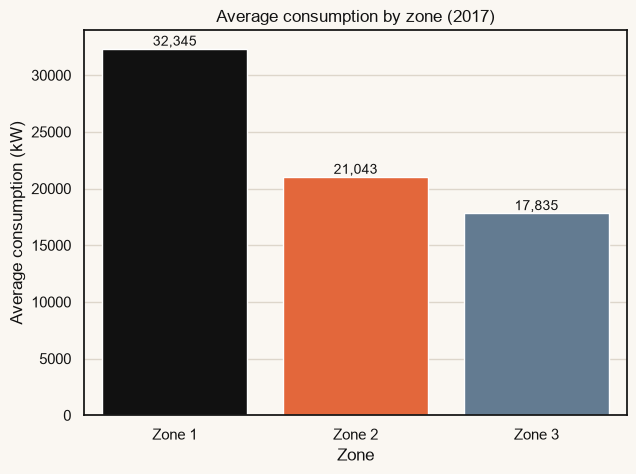

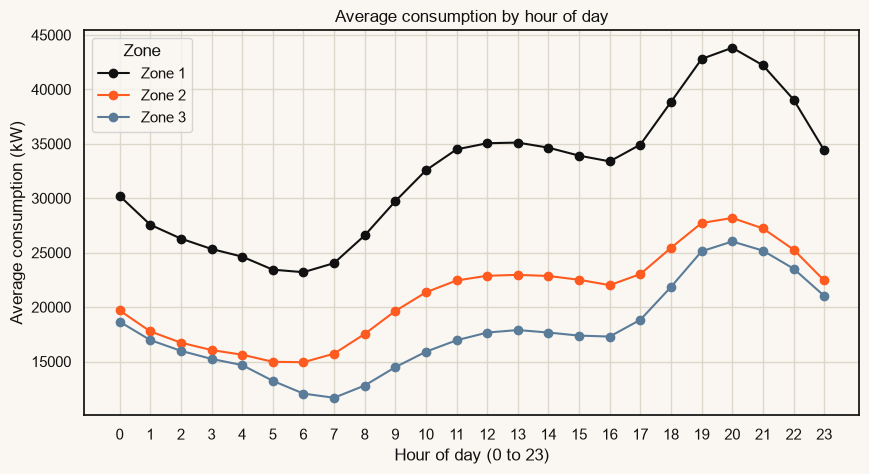

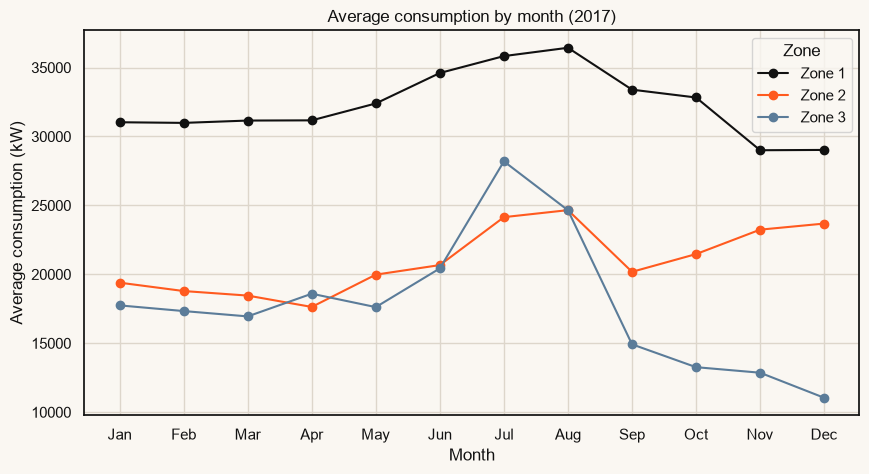

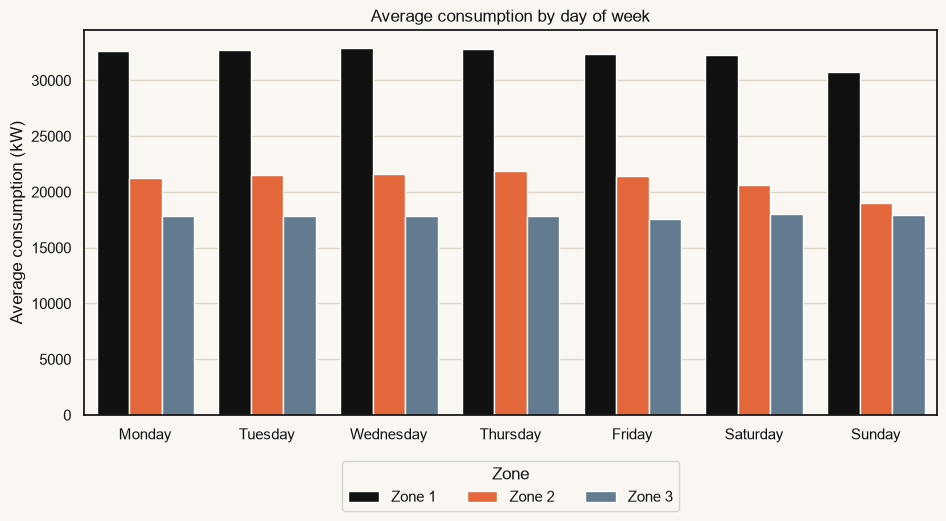

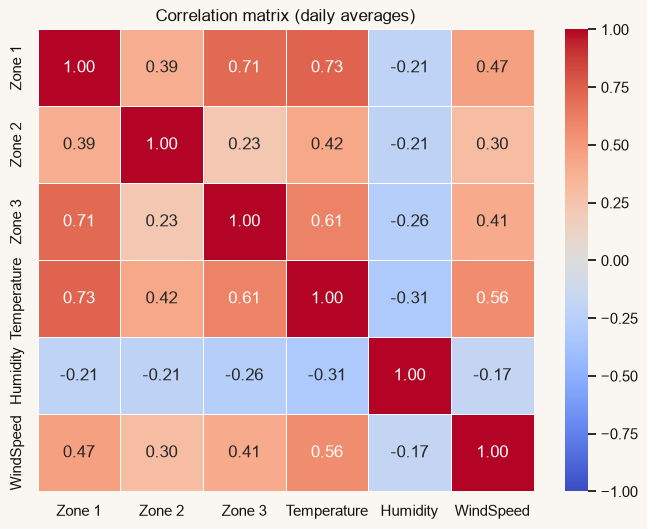

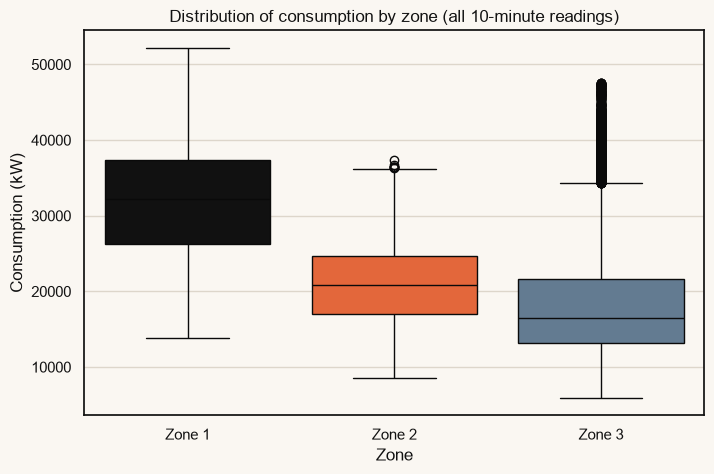

In [ ]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)

# ---- Theme: jet black, soft white, flame orange ----
BG = '#FAF7F2'
sns.set_theme(style='whitegrid', rc={
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG,
    'axes.edgecolor': '#111111', 'axes.labelcolor': '#111111',
    'text.color': '#111111', 'xtick.color': '#111111', 'ytick.color': '#111111',
    'grid.color': '#DDD6CB'
})

zone_names = {'PowerConsumption_Zone1': 'Zone 1',
              'PowerConsumption_Zone2': 'Zone 2',
              'PowerConsumption_Zone3': 'Zone 3'}
zone_colors = {'Zone 1': '#111111', 'Zone 2': '#FF5A1F', 'Zone 3': '#5B7C99'}
env = ['Temperature', 'Humidity', 'WindSpeed']
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# ---- Chart 2: average consumption by zone (Seaborn) ----
avg = df[zones].mean().rename(zone_names).reset_index()
avg.columns = ['Zone', 'Average']
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=avg, x='Zone', y='Average', hue='Zone', palette=zone_colors, legend=False)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.title('Average consumption by zone (2017)')
plt.ylabel('Average consumption (kW)')
plt.savefig('charts/02_average_by_zone.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 3: hourly pattern (Matplotlib) ----
hourly = df.groupby('Hour')[zones].mean().rename(columns=zone_names)
fig, ax = plt.subplots(figsize=(10, 5))
for z in hourly.columns:
    ax.plot(hourly.index, hourly[z], marker='o', label=z, color=zone_colors[z])
ax.set_title('Average consumption by hour of day')
ax.set_xlabel('Hour of day (0 to 23)')
ax.set_ylabel('Average consumption (kW)')
ax.set_xticks(range(0, 24))
ax.legend(title='Zone')
fig.savefig('charts/03_hourly_pattern.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 4: monthly pattern (Matplotlib) ----
monthly = df.groupby('Month')[zones].mean().rename(columns=zone_names)
fig, ax = plt.subplots(figsize=(10, 5))
for z in monthly.columns:
    ax.plot(monthly.index, monthly[z], marker='o', label=z, color=zone_colors[z])
ax.set_title('Average consumption by month (2017)')
ax.set_xlabel('Month')
ax.set_ylabel('Average consumption (kW)')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.legend(title='Zone')
fig.savefig('charts/04_monthly_pattern.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 5: day-of-week comparison (Seaborn, legend below the chart) ----
dow = (df.groupby('DayOfWeek')[zones].mean().rename(columns=zone_names)
         .reindex(day_order).reset_index()
         .melt(id_vars='DayOfWeek', var_name='Zone', value_name='Average'))
plt.figure(figsize=(11, 5))
sns.barplot(data=dow, x='DayOfWeek', y='Average', hue='Zone', palette=zone_colors)
plt.title('Average consumption by day of week')
plt.xlabel('')
plt.ylabel('Average consumption (kW)')
plt.legend(title='Zone', loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.savefig('charts/05_day_of_week.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 6b: correlation heatmap (Seaborn) ----
daily_env = df.set_index('Datetime')[zones + env].resample('D').mean()
corr = daily_env.rename(columns=zone_names).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation matrix (daily averages)')
plt.savefig('charts/06b_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

# ---- Chart 7: comparison of the three zones (Seaborn boxplot) ----
zone_long = df[zones].rename(columns=zone_names).melt(var_name='Zone', value_name='kW')
plt.figure(figsize=(8, 5))
sns.boxplot(data=zone_long, x='Zone', y='kW', hue='Zone', palette=zone_colors, legend=False)
plt.title('Distribution of consumption by zone (all 10-minute readings)')
plt.ylabel('Consumption (kW)')
plt.savefig('charts/07_zone_comparison_boxplot.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
import os
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ---- Theme: soft white background, black text ----
BG = '#FAF7F2'
pio.templates['lab'] = go.layout.Template(layout=dict(
    paper_bgcolor=BG, plot_bgcolor=BG, font=dict(color='#111111'),
    xaxis=dict(gridcolor='#DDD6CB'), yaxis=dict(gridcolor='#DDD6CB')
))

def save_plotly(fig, name):
    fig.write_html(f'charts/{name}.html')
    print('Saved', name)

# ---- Chart 1: trend over time, daily values with a 7-day rolling average ----
daily = df.set_index('Datetime')[zones].resample('D').mean().rename(columns=zone_names)
rolling = daily.rolling(7, center=True).mean()

fig = go.Figure()
for z in daily.columns:
    fig.add_trace(go.Scatter(x=daily.index, y=daily[z], mode='lines', opacity=0.25,
                             line=dict(color=zone_colors[z]), legendgroup=z, showlegend=False,
                             name=f'{z} (daily)'))
    fig.add_trace(go.Scatter(x=rolling.index, y=rolling[z], mode='lines',
                             line=dict(color=zone_colors[z], width=3), legendgroup=z,
                             name=f'{z} (7-day average)'))
fig.update_layout(title='Electricity consumption over time (daily average with 7-day trend)',
                  xaxis_title='Date', yaxis_title='Average consumption (kW)',
                  hovermode='x unified', template='lab')
fig.show()
save_plotly(fig, '01_trend_over_time')

# ---- Chart 6a: consumption vs temperature, humidity and wind speed ----
daily_env2 = df.set_index('Datetime')[zones + env].resample('D').mean().reset_index()
daily_env2['Month'] = daily_env2['Datetime'].dt.month
long = daily_env2.melt(id_vars=['Datetime', 'Month'] + env, value_vars=zones,
                       var_name='Zone', value_name='Consumption')
long['Zone'] = long['Zone'].map(zone_names)

for v in env:
    fig = px.scatter(long, x=v, y='Consumption', facet_col='Zone', color='Month',
                     color_continuous_scale='Turbo', opacity=0.75,
                     title=f'Daily average consumption vs {v}',
                     labels={'Consumption': 'Average consumption (kW)'})
    fig.update_layout(template='lab')
    fig.show()
    save_plotly(fig, f'06a_scatter_{v.lower()}')

print(sorted(os.listdir('charts')))

NameError: name 'df' is not defined

In [ ]:
import os
print(sorted(os.listdir('charts')))

['01_trend_over_time.html', '01_trend_over_time.png', '02_average_by_zone.png', '03_hourly_pattern.png', '04_monthly_pattern.png', '05_day_of_week.png', '06a_scatter_humidity.html', '06a_scatter_temperature.html', '06a_scatter_windspeed.html', '06b_correlation_heatmap.png', '07_zone_comparison_boxplot.png', 'newplot.png', 'newplot1']


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('powerconsumption_clean.csv', parse_dates=['Datetime'])
zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

os.makedirs('charts', exist_ok=True)

zone_names = {'PowerConsumption_Zone1': 'Zone 1',
              'PowerConsumption_Zone2': 'Zone 2',
              'PowerConsumption_Zone3': 'Zone 3'}
zone_colors = {'Zone 1': '#111111', 'Zone 2': '#FF5A1F', 'Zone 3': '#5B7C99'}
env = ['Temperature', 'Humidity', 'WindSpeed']

print(df.shape)

(52416, 15)


In [ ]:
import os
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ---- Theme: soft white background, black text ----
BG = '#FAF7F2'
pio.templates['lab'] = go.layout.Template(layout=dict(
    paper_bgcolor=BG, plot_bgcolor=BG, font=dict(color='#111111'),
    xaxis=dict(gridcolor='#DDD6CB'), yaxis=dict(gridcolor='#DDD6CB')
))

def save_plotly(fig, name):
    fig.write_html(f'charts/{name}.html')
    print('Saved', name)

# ---- Chart 1: trend over time, daily values with a 7-day rolling average ----
daily = df.set_index('Datetime')[zones].resample('D').mean().rename(columns=zone_names)
rolling = daily.rolling(7, center=True).mean()

fig = go.Figure()
for z in daily.columns:
    fig.add_trace(go.Scatter(x=daily.index, y=daily[z], mode='lines', opacity=0.25,
                             line=dict(color=zone_colors[z]), legendgroup=z, showlegend=False,
                             name=f'{z} (daily)'))
    fig.add_trace(go.Scatter(x=rolling.index, y=rolling[z], mode='lines',
                             line=dict(color=zone_colors[z], width=3), legendgroup=z,
                             name=f'{z} (7-day average)'))
fig.update_layout(title='Electricity consumption over time (daily average with 7-day trend)',
                  xaxis_title='Date', yaxis_title='Average consumption (kW)',
                  hovermode='x unified', template='lab')
fig.show()
save_plotly(fig, '01_trend_over_time')

# ---- Chart 6a: consumption vs temperature, humidity and wind speed ----
daily_env2 = df.set_index('Datetime')[zones + env].resample('D').mean().reset_index()
daily_env2['Month'] = daily_env2['Datetime'].dt.month
long = daily_env2.melt(id_vars=['Datetime', 'Month'] + env, value_vars=zones,
                       var_name='Zone', value_name='Consumption')
long['Zone'] = long['Zone'].map(zone_names)

for v in env:
    fig = px.scatter(long, x=v, y='Consumption', facet_col='Zone', color='Month',
                     color_continuous_scale='Turbo', opacity=0.75,
                     title=f'Daily average consumption vs {v}',
                     labels={'Consumption': 'Average consumption (kW)'})
    fig.update_layout(template='lab')
    fig.show()
    save_plotly(fig, f'06a_scatter_{v.lower()}')

print(sorted(os.listdir('charts')))

Saved 01_trend_over_time


Saved 06a_scatter_temperature


Saved 06a_scatter_humidity


Saved 06a_scatter_windspeed
['01_trend_over_time.html', '01_trend_over_time.png', '02_average_by_zone.png', '03_hourly_pattern.png', '04_monthly_pattern.png', '05_day_of_week.png', '06a_scatter_humidity.html', '06a_scatter_temperature.html', '06a_scatter_windspeed.html', '06b_correlation_heatmap.png', '07_zone_comparison_boxplot.png', 'newplot.png', 'newplot1']


**Business Insights and Recommendations**
Key Findings

1. Demand peaks every evening, at 20:00, in all three zones.

Average consumption bottoms out at 06:00 to 07:00 and climbs to a peak at 20:00 (Zone 1 about 43,800 kW, Zone 2 about 28,100 kW, Zone 3 about 26,000 kW), roughly double the early-morning low.
What it means: the evening window of about 18:00 to 21:00 is when the system is under the most stress, so capacity and supply planning should be sized for it.

2. July and August are the annual peak period.

Zones 1 and 2 peak in August (about 36,435 kW and 24,656 kW) and Zone 3 peaks in July (about 28,194 kW). The highest single readings all occur in the evening, on 24 July (Zones 2 and 3) and 7 August (Zone 1).
What it means: the combination of the summer season and the evening peak is the highest-risk period for the year.

3. Zone 3 is the most seasonal and the least predictable zone.

Its coefficient of variation is 37.1%, against 24.7% for Zone 2 and 22.0% for Zone 1. It rises about 2.6 times from December (about 11,045 kW) to July, and falls about 39% from August to September.
What it means: a flat annual plan will not fit Zone 3. It needs its own seasonal planning and closer monitoring.

4. Zone 1 is the largest and steadiest zone, and the zones differ in scale.

Zone 1 averages about 32,345 kW, which is about 1.5 times Zone 2 (about 21,042 kW) and about 1.8 times Zone 3 (about 17,835 kW). Its highest month is only about 26% above its lowest.
What it means: Zone 1 is the baseline load that carries most of the total demand, and small percentage changes in it matter more in absolute terms than large changes in Zone 3.

5. Weekends are lower in Zones 1 and 2, but not in Zone 3.

Weekend average consumption is about 3.5% lower in Zone 1 and 8.2% lower in Zone 2, and about 1.2% higher in Zone 3. Several of the lowest days in Zones 1 and 2 fall on Sundays.
What it means: weekday and weekend schedules can differ for Zones 1 and 2, whereas Zone 3 follows no clear weekly cycle.

6. Temperature is the environmental factor most associated with consumption, and the link is stronger in summer.

On daily averages the correlation with temperature is 0.73 (Zone 1), 0.61 (Zone 3) and 0.42 (Zone 2). It stays positive after removing the hour-of-day pattern (0.51, 0.33 and 0.54). Zone 3 responds in summer (0.50) but hardly in winter (0.09).

Humidity (weakly negative) and wind speed are much weaker and less reliable.

What it means: temperature forecasts are a useful input for demand planning, especially in warm months. This is an association and does not prove that temperature causes the change.

Recommendations:

Plan supply and staffing around the evening peak (finding 1). Schedule planned maintenance, load-shedding trials and demand-response measures outside 18:00 to 21:00, and consider incentives that move flexible loads away from the 20:00 peak.

Prepare extra capacity and a monitoring plan for July and August (findings 2 and 3). Review capacity and contingency arrangements before summer, with particular attention to Zone 3, and set alert thresholds based on the 2017 summer peak levels.

Use separate planning profiles for each zone (findings 3 to 5). Plan Zone 3 on a seasonal basis, use weekday and weekend profiles for Zones 1 and 2, and treat Zone 1 as the stable base load.
Add temperature forecasts to demand planning (finding 6). Feed daily temperature forecasts into short-term demand planning for the warm months, as a starting point for a forecasting model, and test it against new data before relying on it.

Improve data collection (limitations below). Verify the unit of the consumption readings, confirm the definitions of the two diffuse flow columns, and check the wind speed sensor or its coding.
Limitations
The data covers one year (1 January to 30 December 2017), so the patterns describe 2017 and cannot be confirmed as repeating cycles.

The consumption readings are treated as average power in kW, not energy per interval, because the unit in the data dictionary is unclear. Results are therefore reported as averages, not totals.
Correlation does not prove causation. Temperature, time of day and season move together, and other factors could drive both.

Wind speed takes almost only two values (about 0.08 and about 4.9), so its relationship with consumption should be treated with caution.
The two diffuse flow columns were not analysed, because their description in the data dictionary could not be verified.